<h1>VQE for the Heisenberg Model</h1>

Simulating quantum systems is one of the main applications proposed for current and near-term quantum computers. Hybrid classical-quantum approaches, such as Variational Quantum Algorithms (VQAs), are promising candidates for this in the current Noisy Intermediate Scale Quantum, or NISQ, era. This hybrid approach involves running a quantum circuit on a quantum processing unit (QPU), while doing the optimisation of circuit parameters classically.

<h2> The Heisenberg Model </h2>

The Heisenberg model is an important model used to study the properties of magnetic systems. In the model, microscopic magnetic dipole moments in the system are modeled as spins on lattice sites, which can point in two directions: up or down. Simulating such a quantum system is a difficult task for classical computers, and one where quantum computers may show advantage over classical methods.
The Heisenberg model is described by a Hamiltonian defined as
$$\hat{H} = -J\sum_{j=1}^N{\sigma}_j^x{\sigma}_{j+1}^x+{\sigma}_j^y{\sigma}_{j+1}^y+{\sigma}_j^z{\sigma}_{j+1}^z - h\sum_{j=1}^N\sigma_j^z,$$
where $\sigma_j$ are Pauli matrices representing the spins in the spin chain, $J$ is the coupling constant describing the strength of the interaction between the spins, and $h$ is the strength of an external magnetic field. In the absence of an applied magnetic field, $h = 0$, and the Hamiltonian reduces to
$$\hat{H} = -J\sum_{j=1}^N{\sigma}_j^x{\sigma}_{j+1}^x+{\sigma}_j^y{\sigma}_{j+1}^y+{\sigma}_j^z{\sigma}_{j+1}^z.$$

In this case, the model is fully characterised by the exchange interaction $J$ between the spins in the system. The spin alignment of such a system is determined by which alignment is the most energetically favorable, resulting in the lowest energy.

For $J > 0$: spins prefer to align with each other $\rightarrow$ ferromagnetic<br>
For $J < 0$: spins prefer to point in opposite directions $\rightarrow$ antiferromagnetic [1].

<h2>Variational Quantum Eigensolver (VQE)</h2>

Variational Quantum Algorithms (VQAs) are a type of hybrid quantum-classical algorithm designed to work with the currently available noisy quantum computers. In a VQA, a parametrized quantum circuit is executed on a quantum computer and the circuit parameters are optimized classically with the goal of minimizing a cost function [2].

Variational Quantum Eigensolvers are a type of variational quantum algorithm designed for the purpose of finding the ground state of a quantum system or molecule. In a VQE, the cost function to be minimized in the classical optimization loop is the energy of the system given by the expectation value of the Hamiltonian, which once minimized gives the ground state energy of the system:

$$ E_0 = \text{min}_\theta⟨\psi(\theta)|H|\psi(\theta)⟩, $$

where $|\psi(\theta)⟩$ is the quantum state prepared by the parametrised circuit. By iteratively updating $\theta$
with a classical optimizer, the algorithm converges toward the ground state energy [2]. 

In this notebook, we implement VQE for the Heisenberg model.

<h2>Heisenberg model VQE</h2>

<h3> Importing libraries </h3>

In [1]:
# For visualization and other useful tools
import matplotlib.pyplot as plt
%matplotlib inline
from qiskit.visualization import plot_histogram
import numpy as np
from typing import List

# For the quantum part
from qiskit import QuantumCircuit
from qiskit.circuit.library import EfficientSU2
from qiskit.quantum_info import SparsePauliOp, pauli_basis, Operator
from qiskit.primitives import StatevectorEstimator
from qiskit_ibm_runtime import Estimator, Session, Options
from qiskit.compiler import transpile

# For classical optimization
""" importing optimization part from a separate file: learning_algorithm.py
    (or learning_algorithm_REM.py for readout error mitigation but initial layout needs to be selected in that file)"""
import sys
import os

sys.path.append(os.path.abspath('..'))
from Learning_Algorithm.learning_algorithm import Learning

# For backend
from iqm import qiskit_iqm
from iqm.qiskit_iqm.fake_backends import fake_aphrodite
from iqm.qiskit_iqm import IQMProvider
from qiskit_aer import AerSimulator

<h3>Setting backend</h3>

In [2]:
# UNCOMMENT YOUR CHOICE OF BACKEND

backend = AerSimulator()                          # fake backend without noise
#backend = fake_aphrodite.IQMFakeAphrodite()      # fake Q50
target = backend.target

# Helmi (VTT Q5) 5-qubit quantum computer (requires access)
HELMI_CORTEX_URL = os.getenv('HELMI_CORTEX_URL')
# provider = IQMProvider(HELMI_CORTEX_URL)
# backend = provider.get_backend()

# Q50 (VTT Q50) 52-qubit quantum computer (requires access)
Q50_CORTEX_URL = os.getenv('Q50_CORTEX_URL')
# provider_q50 = IQMProvider(Q50_CORTEX_URL)
# backend = provider_q50.get_backend()

<h3>Setting model parameters</h3>

In [3]:
n = 4         # number of spins/qubits
J = 1.0       # coupling constant

<h3>Defining Hamiltonian</h3>

In [4]:
def heisenberg_sparse_pauli_op(n_qubits, J):
    paulis = []
    coeffs = []
    
    for i in range(n_qubits - 1):
        for pauli in ['XX', 'YY', 'ZZ']:
            label = ['I'] * n_qubits
            label[i] = pauli[0]
            label[i+1] = pauli[1]
            paulis.append(''.join(label))
            coeffs.append(-J)
    
    return SparsePauliOp(paulis, coeffs=np.array(coeffs, dtype=float))

heisenberg_hamiltonian = heisenberg_sparse_pauli_op(n, J)

<h3>Parametrised quantum circuit</h3>

Defining the ansatz and printing it: 

/tmp/ipykernel_162355/47788449.py:34: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, _ in circuit.data:
/tmp/ipykernel_162355/47788449.py:43: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, cargs in circuit.data:


Ansatz:
Number of parameters: 16
Total number of gates 22
Figure(872.774x367.889)


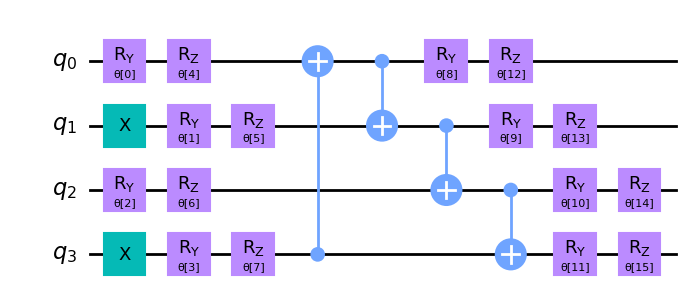

In [5]:
def ansatz_function(n, J):

    SU2_ansatz = EfficientSU2(n, reps=1, entanglement="circular")
    
    # For positive J -> initial state for antiferromagnetic order
    if J > 0:
        def create_neel_state(num_qubits):
            qc = QuantumCircuit(num_qubits)
            for qubit in range(num_qubits):
                if qubit % 2 == 1:
                    qc.x(qubit)
            return qc
        # initial Neel state |010101...>
        neel_state = create_neel_state(n)
        ansatz = neel_state.compose(SU2_ansatz)
    # For negative J -> initial state for ferromagnetic order
    elif J < 0:
        # initial superposition state |0000...> + |1111...>
        ferro_initial = QuantumCircuit(n)
        ferro_initial.h(range(n)) 
        ansatz = ferro_initial.compose(SU2_ansatz)
    return ansatz

circuit = ansatz_function(n, J)

# Transpiling the circuit
circuit_transpiled = transpile(circuit, target=backend.target, layout_method="trivial", routing_method = "sabre", optimization_level=3)

# Removing unused qubits
# (estimator requires same qubit number for observable and circuit, IQM backends add idle qubits during transpilation)
def remove_unused_qubits(circuit: QuantumCircuit) -> QuantumCircuit:
    # Identify used qubits
    used_qubits = set()
    for instr, qargs, _ in circuit.data:
        for qubit in qargs:
            used_qubits.add(qubit)

    # Map old qubits to new indices
    qubit_map = {qubit: idx for idx, qubit in enumerate(sorted(used_qubits, key=lambda q: circuit.qubits.index(q)))}
    new_circ = QuantumCircuit(len(used_qubits))

    # Rebuild the circuit
    for instr, qargs, cargs in circuit.data:
        new_qargs = [new_circ.qubits[qubit_map[q]] for q in qargs]
        new_circ.append(instr, new_qargs, cargs)

    return new_circ

ansatz = remove_unused_qubits(circuit_transpiled)

print("Ansatz:")
print("Number of parameters:", ansatz.num_parameters)
print("Total number of gates", len(ansatz))
print(ansatz.draw('mpl', style="clifford"))

<h3>Classical optimization</h3>

For conciseness, the classical optimization loop has been imported from a separate file _learning_algorithm.py_. The classical optimizer can be selected here, but other changes to optimizer settings or adding new optimizer options can be done by editing _learning_algorithm.py_.

In [6]:
# Matching Hamiltonian and circuit dimensions (required by estimator)
def pad_hamiltonian(ham: SparsePauliOp, total_qubits: int) -> SparsePauliOp:
    current_qubits = ham.num_qubits
    if current_qubits == total_qubits:
        return ham
    elif current_qubits > total_qubits:
        raise ValueError("Hamiltonian has more qubits than the circuit.")

    # Pad with identities on the left (least significant qubits)
    n_pad = total_qubits - current_qubits
    padding = SparsePauliOp.from_list([('I' * n_pad, 1.0)])
    padded_ham = ham.tensor(padding)
    return padded_ham

hamiltonian = pad_hamiltonian(heisenberg_hamiltonian, ansatz.num_qubits)

"""Choosing optimizer (options include: "BFGS", "SPSA", "basinhopping", "dual_annealing", "cobyla", and "gp_minimize")
SPSA is recommended for running on real QPU (most tolerant against noise and uses only 2 circuit runs per iteration)"""
optimizer = "cobyla"
#estimator = StatevectorEstimator()         # can be used with simulators only
estimator = Estimator(mode=backend)         # can be used with simulators and with real QPUs

# Running optimization loop
learning = Learning(ansatz, hamiltonian, backend, estimator, optimizer)
result = learning.run()
energy_achieved = learning.cost


Iterations: 1 | Current cost: 1.0576171875

Iterations: 2 | Current cost: 1.14013671875

Iterations: 3 | Current cost: 0.4794921875

Iterations: 4 | Current cost: -0.64892578125

Iterations: 5 | Current cost: -0.775390625

Iterations: 6 | Current cost: -0.7783203125

Iterations: 7 | Current cost: -0.6708984375

Iterations: 8 | Current cost: -0.1484375

Iterations: 9 | Current cost: -0.7841796875

Iterations: 10 | Current cost: -1.33740234375

Iterations: 11 | Current cost: -0.5927734375

Iterations: 12 | Current cost: -0.94775390625

Iterations: 13 | Current cost: -1.18701171875

Iterations: 14 | Current cost: -1.23974609375

Iterations: 15 | Current cost: -1.1162109375

Iterations: 16 | Current cost: -0.74853515625

Iterations: 17 | Current cost: -0.72265625

Iterations: 18 | Current cost: -1.37548828125

Iterations: 19 | Current cost: -1.24462890625

Iterations: 20 | Current cost: -1.1640625

Iterations: 21 | Current cost: -0.3427734375

Iterations: 22 | Current cost: -1.02978515625

<h3>Transpiling</h3>


Transpiled circuit:
Figure(1416.5x451.5)

Transpiled circuit gates:
OrderedDict([('u3', 8), ('cx', 4), ('measure', 4), ('barrier', 1)])
Transpiled circuit number of parameters 0


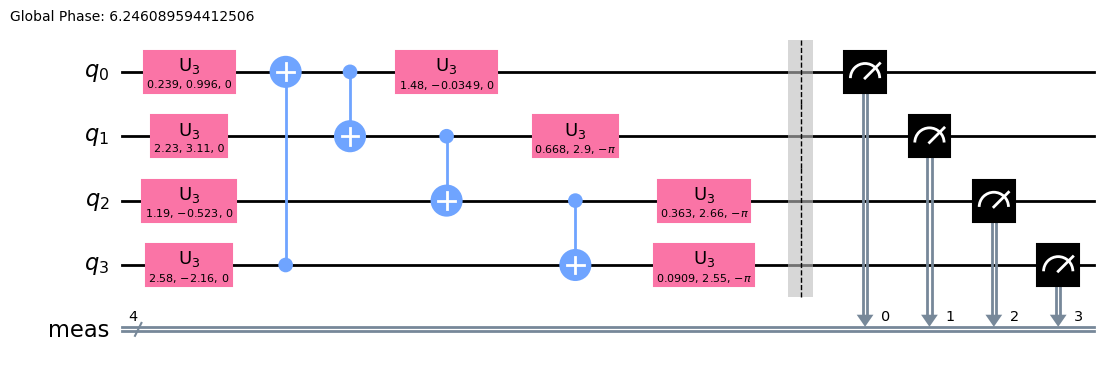

In [7]:
values = learning.params
bound_circuit = ansatz.assign_parameters(values)
bound_circuit.measure_all()

print()
transpiled_job = transpile(bound_circuit, backend, optimization_level=3)
print("Transpiled circuit:")
print(transpiled_job.draw('mpl', style="clifford"))
print()
print("Transpiled circuit gates:")
print(transpiled_job.count_ops())
print("Transpiled circuit number of parameters", transpiled_job.num_parameters)

<h3>Results</h3>

In [8]:
# Printing calculated ground state energy (final cost) and final circuit parameters
print(f"Iterations: {learning.costs_dictionary['iterations']} | Current cost: {learning.energy}")
print()
print(f'Calculated ground state energy: {learning.cost}')
print()
print(f'Calculated parameters: {learning.params}')

# Finding exact ground state energy
H_matrix = Operator(heisenberg_hamiltonian).data
eigenvalues = np.linalg.eigvalsh(H_matrix)
exact_ground_state = np.min(eigenvalues)
print()
print("Minimum eigenvalue (exact ground state):", exact_ground_state)
error = learning.cost-np.min(eigenvalues)
print(f"Error: {error}")

Iterations: 162 | Current cost: -1.9375

Calculated ground state energy: -1.9375

Calculated parameters: [ 0.23891344  0.91033095  1.19087791  0.56629858  0.99580712 -0.03036336
 -0.52338329  0.98641383  1.47818357 -0.66784209 -0.36264225 -0.09091011
 -0.03486271 -0.24523903 -0.4862678  -0.58791333]

Minimum eigenvalue (exact ground state): -3.0
Error: 1.0625


Calculating and printing the exact ground state energy through finding the minimum eigenvalue of the Hamiltonian:

<h3>Plotting energy convergence</h3>

Plotting the resulting convergence of energy to the ground state energy:

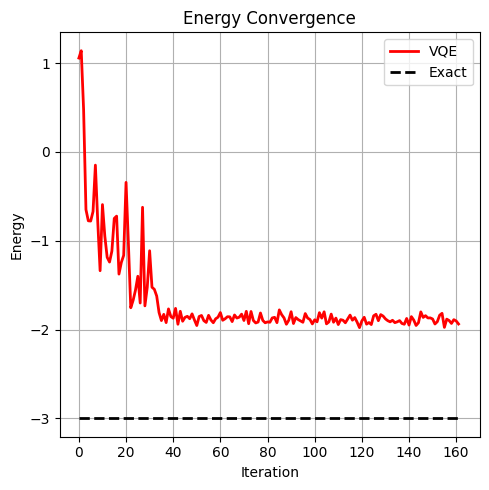

In [9]:
energies = learning.costs_dictionary["costs"]
num_iters = len(learning.costs_dictionary["costs"])

f1 = plt.figure(figsize=(5,5))
ax1 = f1.add_subplot(1, 1, 1)
plt.plot(energies, label='VQE', color = 'red', linewidth=2.0)
plt.hlines(exact_ground_state, xmin=0, xmax=round(num_iters), label='Exact', color='black', linestyles='dashed', linewidth=2.0)
plt.xlabel("Iteration")
plt.ylabel("Energy")
plt.title("Energy Convergence")
plt.grid(True)
plt.tight_layout()
plt.legend()
plt.show()

<h2>Results: Investigating magnetic order</h2>

The bitstrings of the state with all zeros $\ket{0000...}$ corresponds to all spins up, and the state with all ones corresponds to all spins down $\ket{1111...}$, and therefore correspond to ferromagnetic order. The Heisenberg model with $J > 0$ is ferromagnetic, so for positive $J$ the counts should reflect this, having most counts for these states.

On the other hand the state $\ket{010101...}$ corresponds to every other spin in the chain being up, and every other spin being down. The Heisenberg model for $J < 0$ is antiferromagnetic, so for negative $J$ most of the counts should be for this state and other states similar to it.

<h3>Defining function for getting counts and histograms</h3>

In [10]:
def get_counts_and_histogram(n, J, backend):
    circuit_transpiled = transpile(ansatz_function(n, J), target=backend.target, layout_method = "trivial", routing_method = "sabre", optimization_level=3)
    ansatz = remove_unused_qubits(circuit_transpiled)
    heisenberg_hamiltonian = heisenberg_sparse_pauli_op(n, J)
    hamiltonian = pad_hamiltonian(heisenberg_hamiltonian, ansatz.num_qubits)
    learning = Learning(ansatz, hamiltonian, backend, estimator, optimizer)
    result = learning.run()
    
    values = learning.params
    bound_circuit = ansatz.assign_parameters(values)
    bound_circuit.measure_all()

    transpiled_job = transpile(bound_circuit, backend)

    job = backend.run(transpiled_job, shots=1000)
    print()
    print("Counts:")
    print(job.result().get_counts())
    fig = plot_histogram(job.result().get_counts())
    fig.savefig("my_histogram.png")
    if J > 0:
        plt.title("Ferromagnetic order")
    if J < 0:
        plt.title("Antiferromagnetic order")
    plt.show()

<h3>Antiferromagnetic order without noise</h3>

/tmp/ipykernel_162355/47788449.py:34: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, _ in circuit.data:
/tmp/ipykernel_162355/47788449.py:43: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, cargs in circuit.data:



Iterations: 1 | Current cost: 1.0078125

Iterations: 2 | Current cost: 0.56298828125

Iterations: 3 | Current cost: 0.15576171875

Iterations: 4 | Current cost: -0.3134765625

Iterations: 5 | Current cost: -0.28955078125

Iterations: 6 | Current cost: -0.48193359375

Iterations: 7 | Current cost: -0.29150390625

Iterations: 8 | Current cost: -0.97314453125

Iterations: 9 | Current cost: -0.4130859375

Iterations: 10 | Current cost: -0.630859375

Iterations: 11 | Current cost: -1.583984375

Iterations: 12 | Current cost: -1.298828125

Iterations: 13 | Current cost: -1.56884765625

Iterations: 14 | Current cost: -1.30908203125

Iterations: 15 | Current cost: -1.87939453125

Iterations: 16 | Current cost: -1.4873046875

Iterations: 17 | Current cost: -2.04833984375

Iterations: 18 | Current cost: -2.208984375

Iterations: 19 | Current cost: -2.0576171875

Iterations: 20 | Current cost: -2.3388671875

Iterations: 21 | Current cost: -2.5361328125

Iterations: 22 | Current cost: -2.39892578

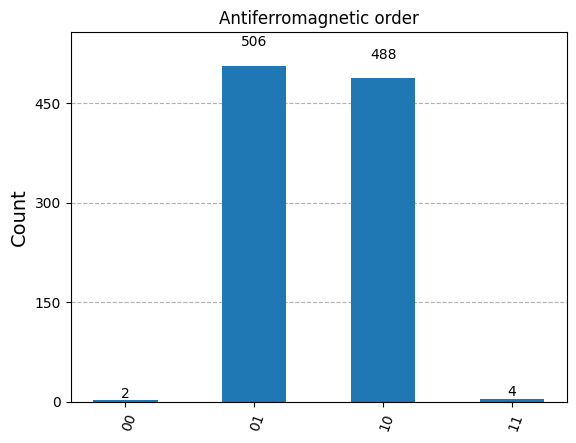

In [11]:
n = 2     # number of spins/qubits
J = -1.0   # coupling constant

backend = AerSimulator()

get_counts_and_histogram(n, J, backend)

<h3> Antiferromagnetic order with noise</h3>

/tmp/ipykernel_162355/47788449.py:34: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, _ in circuit.data:
/tmp/ipykernel_162355/47788449.py:43: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, cargs in circuit.data:



Iterations: 1 | Current cost: 3.015625

Iterations: 2 | Current cost: 2.11572265625

Iterations: 3 | Current cost: 1.41552734375

Iterations: 4 | Current cost: -0.06298828125

Iterations: 5 | Current cost: -0.689453125

Iterations: 6 | Current cost: -1.10986328125

Iterations: 7 | Current cost: -1.21630859375

Iterations: 8 | Current cost: -1.7734375

Iterations: 9 | Current cost: -1.80419921875

Iterations: 10 | Current cost: -1.537109375

Iterations: 11 | Current cost: -0.81005859375

Iterations: 12 | Current cost: -1.49609375

Iterations: 13 | Current cost: -1.32470703125

Iterations: 14 | Current cost: -1.6748046875

Iterations: 15 | Current cost: -1.96142578125

Iterations: 16 | Current cost: -1.79052734375

Iterations: 17 | Current cost: -2.62890625

Iterations: 18 | Current cost: -2.7265625

Iterations: 19 | Current cost: -2.43798828125

Iterations: 20 | Current cost: -2.16943359375

Iterations: 21 | Current cost: -3.474609375

Iterations: 22 | Current cost: -3.64111328125

Ite

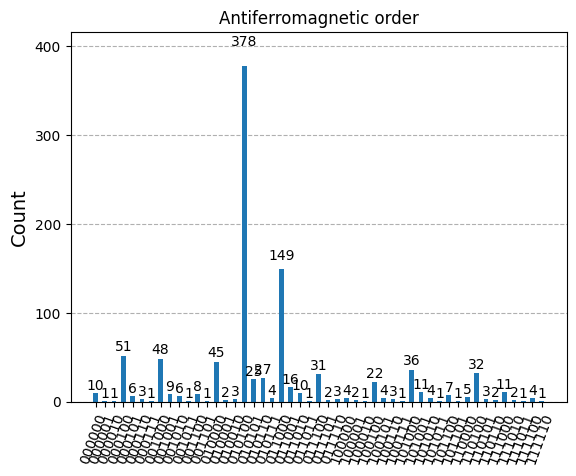

In [12]:
n = 4     # number of spins/qubits
J = -1.0   # coupling constant

backend = fake_aphrodite.IQMFakeAphrodite()

get_counts_and_histogram(n, J, backend)

/tmp/ipykernel_162355/47788449.py:34: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, _ in circuit.data:
/tmp/ipykernel_162355/47788449.py:43: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, cargs in circuit.data:



Iterations: 1 | Current cost: 2.95263671875

Iterations: 2 | Current cost: 2.57421875

Iterations: 3 | Current cost: 2.0849609375

Iterations: 4 | Current cost: 1.49267578125

Iterations: 5 | Current cost: 0.40087890625

Iterations: 6 | Current cost: -0.06298828125

Iterations: 7 | Current cost: -0.38134765625

Iterations: 8 | Current cost: -0.5986328125

Iterations: 9 | Current cost: -0.642578125

Iterations: 10 | Current cost: -1.1904296875

Iterations: 11 | Current cost: -1.31103515625

Iterations: 12 | Current cost: -1.32275390625

Iterations: 13 | Current cost: -0.89404296875

Iterations: 14 | Current cost: -0.76171875

Iterations: 15 | Current cost: -0.43115234375

Iterations: 16 | Current cost: -1.57080078125

Iterations: 17 | Current cost: -1.3896484375

Iterations: 18 | Current cost: -1.67822265625

Iterations: 19 | Current cost: -1.5810546875

Iterations: 20 | Current cost: -2.11474609375

Iterations: 21 | Current cost: -1.65380859375

Iterations: 22 | Current cost: -1.91455

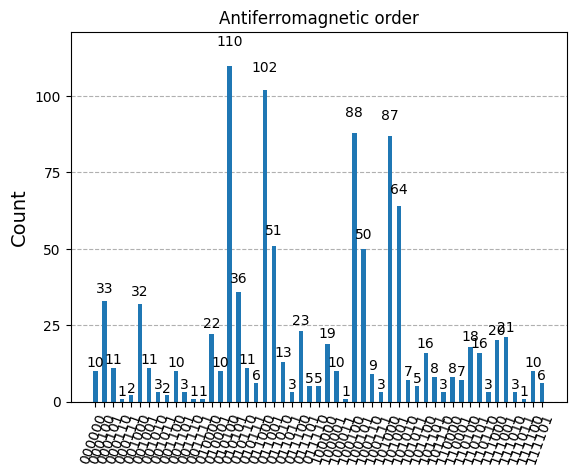

In [13]:
n = 5     # number of spins/qubits
J = -1.0   # coupling constant

get_counts_and_histogram(n, J, backend)

<h3>Ferromagnetic order without noise</h3>

/tmp/ipykernel_162355/47788449.py:34: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, _ in circuit.data:
/tmp/ipykernel_162355/47788449.py:43: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, cargs in circuit.data:



Iterations: 1 | Current cost: -0.052734375

Iterations: 2 | Current cost: -0.025390625

Iterations: 3 | Current cost: -0.46044921875

Iterations: 4 | Current cost: -0.92578125

Iterations: 5 | Current cost: -0.8955078125

Iterations: 6 | Current cost: -1.12255859375

Iterations: 7 | Current cost: -0.5302734375

Iterations: 8 | Current cost: -0.90966796875

Iterations: 9 | Current cost: -0.9501953125

Iterations: 10 | Current cost: -1.0615234375

Iterations: 11 | Current cost: -0.47900390625

Iterations: 12 | Current cost: -0.2724609375

Iterations: 13 | Current cost: -1.53125

Iterations: 14 | Current cost: -1.875

Iterations: 15 | Current cost: -1.841796875

Iterations: 16 | Current cost: -1.8125

Iterations: 17 | Current cost: -1.251953125

Iterations: 18 | Current cost: -1.53466796875

Iterations: 19 | Current cost: -1.287109375

Iterations: 20 | Current cost: -1.90185546875

Iterations: 21 | Current cost: -1.66845703125

Iterations: 22 | Current cost: -1.44970703125

Iterations: 2

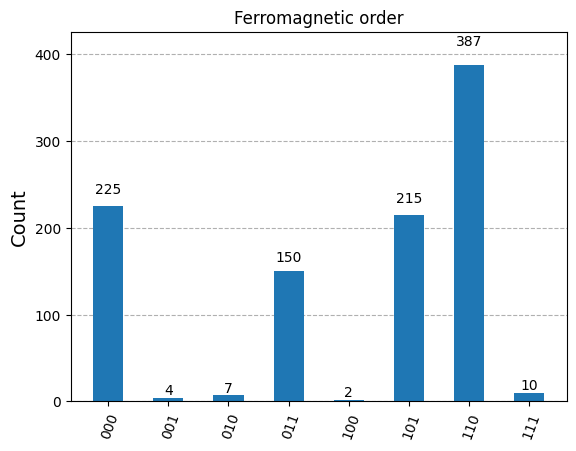

In [14]:
n = 3     # number of spins/qubits
J = 1.0  # coupling constant

backend = AerSimulator()

get_counts_and_histogram(n, J, backend)

/tmp/ipykernel_162355/47788449.py:34: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, _ in circuit.data:
/tmp/ipykernel_162355/47788449.py:43: DeprecationWarning: Treating CircuitInstruction as an iterable is deprecated legacy behavior since Qiskit 1.2, and will be removed in Qiskit 2.0. Instead, use the `operation`, `qubits` and `clbits` named attributes.
  for instr, qargs, cargs in circuit.data:



Iterations: 1 | Current cost: -0.076171875

Iterations: 2 | Current cost: 0.044921875

Iterations: 3 | Current cost: -0.51806640625

Iterations: 4 | Current cost: 0.01123046875

Iterations: 5 | Current cost: -0.94580078125

Iterations: 6 | Current cost: 0.03662109375

Iterations: 7 | Current cost: -0.89892578125

Iterations: 8 | Current cost: -0.8544921875

Iterations: 9 | Current cost: -0.88232421875

Iterations: 10 | Current cost: -0.9609375

Iterations: 11 | Current cost: -0.90380859375

Iterations: 12 | Current cost: -1.103515625

Iterations: 13 | Current cost: -0.27783203125

Iterations: 14 | Current cost: -0.6416015625

Iterations: 15 | Current cost: -1.15185546875

Iterations: 16 | Current cost: -1.46337890625

Iterations: 17 | Current cost: -1.4169921875

Iterations: 18 | Current cost: -1.4736328125

Iterations: 19 | Current cost: -1.34375

Iterations: 20 | Current cost: -0.91845703125

Iterations: 21 | Current cost: -0.99072265625

Iterations: 22 | Current cost: -1.6923828125

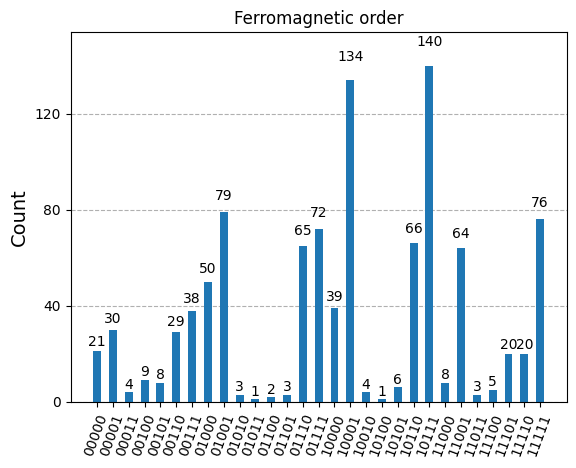

In [15]:
n = 5     # number of spins/qubits
J = 1.0  # coupling constant

backend = AerSimulator()

get_counts_and_histogram(n, J, backend)

<h2>References</h2>

[1]: N. Haboury. “Quantum magnetism”, 2022. Available: https://www.researchgate.net/publication/359011322_Quantum_magnetism.  [Accessed: Aug. 22, 2025]

[2]: M. Cerezo, A. Arrasmith, R. Babbush, et al. “Variational quantum algorithms”, Nat Rev Phys 3, pp. 625–644 (2021). doi: https://doi.org/10.1038/s42254-021-00348-9